# Calibration vs. lost epistemic signal: class-conditional (Mondrian) and decomposition analysis

Runs entirely **post-hoc** on the probabilities that `evaluate_conformal` already saved to `results/noise_testing/{tag}.npz` by `calibration_efficiency.ipynb`.

In [18]:
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch
from scipy import stats
from scipy.optimize import minimize_scalar
from IPython.display import Markdown, display

from pipeline import REPO
from pipeline.evaluate import _sets, mondrian_conformal, DEFAULT_RESULTS_DIR   # the fixed conformal layer
import common      # compute_ece / compute_nll / compute_brier (not re-exported by pipeline)

In [19]:
# ------------------------------- Config ---------------------------------------
plt.style.use("default")
SEEDS = [0, 1, 2, 3, 4]
METHODS = ["baseline", "mc_dropout", "laplace", "sngp", "deep_ensemble"]
LABEL = {"baseline": "Baseline", "mc_dropout": "MC Dropout", "laplace": "Laplace",
         "sngp": "SNGP", "deep_ensemble": "Deep Ensemble"}
COLOR = {"baseline": "#0072B2", "mc_dropout": "#E69F00", "laplace": "#009E73",
         "sngp": "#CC79A7", "deep_ensemble": "#D55E00"}          # colour-blind safe
MARKER = {"baseline": "o", "mc_dropout": "s", "laplace": "^", "sngp": "D", "deep_ensemble": "P"}

SCORES = ("aps_rand", "lac")
SHORT = {"aps_rand": "APS", "lac": "LAC"}
FOCUS = (0.02, 0.05, 0.10)                                  # alphas for Mondrian / per-class / AUROC
ALPHA_GRID = np.round(np.linspace(0.02, 0.10, 9), 4)        # restricted-AUC grid (contains FOCUS)
ALPHA_DECOMP = 0.05                                         # alpha for the headline plots
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

OUT_DIR = REPO / "results" / "calibration_efficiency" / "mondrian_analysis"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "stix", "font.size": 8,
                     "axes.titlesize": 8, "axes.labelsize": 8, "legend.fontsize": 7,
                     "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.linewidth": 0.6,
                     "pdf.fonttype": 42, "savefig.bbox": "tight", "savefig.dpi": 300})
FULL_W = 7.1 # inches, full-width figure for a two-column paper

TABLES = [] # (title, markdown) collected for tables.md
def md_table(headers, body):
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    return "\n".join(lines + ["| " + " | ".join(map(str, r)) + " |" for r in body])

def show(title, md_text):
    TABLES.append((title, md_text))
    display(Markdown(f"**{title}**\n\n{md_text}"))

def finish(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf"); fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

## 1. Helpers and per-run analysis

For every (method, seed) run the cell loads the cached calibration/test probabilities and computes, for both the raw probabilities and a **temperature-scaled** copy (T fitted on the calibration split by minimising NLL, similar to Xi et al. in our paper):

- accuracy, ECE, NLL, Brier;
- Mondrian set size and per-class coverage, per-class coverage and size of the *marginal* sets, and the AUROC of set size for detecting the model's own top-1 errors.

In [20]:
_trapz = getattr(np, "trapezoid", None) or np.trapz
def gi(a): return int(np.argmin(np.abs(ALPHA_GRID - a)))      # index of alpha in ALPHA_GRID
def ak(a): return f"{int(round(a * 100)):02d}"                # 0.05 -> "05"

def load_run(method, seed):
    tag = f"{method}_noise0_seed{seed}"
    path = DEFAULT_RESULTS_DIR / f"{tag}.npz"
    if not path.exists():
        raise FileNotFoundError(f"{path} not found - run calibration_efficiency.ipynb first "
                                f"(evaluate_conformal saves the .npz files)")
    z = np.load(path)
    return tag, z["cal_probs"], z["cal_labels"], z["test_probs"], z["test_labels"]

def fit_temperature(probs, labels):
    logp = np.log(np.clip(probs, 1e-12, 1.0)); idx = np.arange(len(labels))
    def nll(T):
        z = logp / T; z = z - z.max(1, keepdims=True)
        return float(-(z[idx, labels] - np.log(np.exp(z).sum(1))).mean())
    return float(minimize_scalar(nll, bounds=(0.05, 10.0), method="bounded").x)

def apply_temperature(probs, T):
    z = np.log(np.clip(probs, 1e-12, 1.0)) / T; z = z - z.max(1, keepdims=True)
    e = np.exp(z); return e / e.sum(1, keepdims=True)

def basic_metrics(p, y):
    ece, _ = common.compute_ece(p, y)
    return dict(accuracy=float((p.argmax(1) == y).mean()), ece=ece,
                nll=common.compute_nll(p, y), brier=common.compute_brier(p, y))

def auroc(score, positive):
    # P(score of a random positive > score of a random negative), ties count 1/2 (Mann-Whitney)
    positive = np.asarray(positive, bool); n_pos, n_neg = positive.sum(), (~positive).sum()
    if n_pos == 0 or n_neg == 0: return float("nan")
    r = stats.rankdata(score)
    return float((r[positive].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))

In [21]:
def analyze_run(method, seed):
    tag, cp, cy, tp, ty = load_run(method, seed)
    n, K = tp.shape; idx = np.arange(n)
    T = fit_temperature(cp, cy)
    variants = {"raw": (cp, tp), "ts": (apply_temperature(cp, T), apply_temperature(tp, T))}
    err = tp.argmax(1) != ty

    out = dict(model=method, seed=seed, tag=tag, T=T,
               metrics={v: basic_metrics(variants[v][1], ty) for v in variants},
               sizes={v: {} for v in variants}, cover={v: {} for v in variants},
               mond={}, pc_cov={}, pc_size={}, dist={}, auroc={},
               auroc_unc={"conf": auroc(1 - tp.max(1), err),
                          "entropy": auroc(-(tp * np.log(np.clip(tp, 1e-12, 1))).sum(1), err)})

    for v, (c_p, t_p) in variants.items():
        for sc in SCORES:
            sz, cv = [], []
            for a in ALPHA_GRID:
                S = _sets(c_p, cy, t_p, float(a), sc, seed)
                s, hit = S.sum(1), S[idx, ty]
                sz.append(float(s.mean())); cv.append(float(hit.mean()))
                if v == "raw" and any(np.isclose(a, f) for f in FOCUS):
                    fa = min(FOCUS, key=lambda f: abs(f - a))
                    out["pc_cov"].setdefault(fa, {})[sc] = np.array([hit[ty == c].mean() for c in range(K)])
                    out["pc_size"].setdefault(fa, {})[sc] = np.array([s[ty == c].mean() for c in range(K)])
                    out["dist"].setdefault(fa, {})[sc] = np.array([(s == 0).mean(), (s == 1).mean(),
                                                                   (s == 2).mean(), (s >= 3).mean()])
                    out["auroc"].setdefault(fa, {})[sc] = auroc(s, err)
                    m = mondrian_conformal(cp, cy, tp, ty, alpha=float(a), score=sc, seed=seed)
                    out["mond"].setdefault(fa, {})[sc] = dict(avg_set_size=m["avg_set_size"],
                                                              frac_empty=m["frac_empty"],
                                                              coverage=m["coverage"],
                                                              per_class_coverage=m["per_class_coverage"])
            out["sizes"][v][sc] = np.array(sz); out["cover"][v][sc] = np.array(cv)

    # consistency check against the result file evaluate_conformal wrote (alpha = 0.1)
    jp = DEFAULT_RESULTS_DIR / f"{tag}.json"
    if jp.exists():
        ref = json.load(open(jp))["conformal"]["aps_rand"]["avg_set_size"]
        mine = out["sizes"]["raw"]["aps_rand"][gi(0.10)]
        if not np.isclose(ref, mine, rtol=1e-6):
            print(f"  WARNING {tag}: APS size@0.1 {mine:.5f} != saved {ref:.5f}")
    return out

runs = []
for m in METHODS:
    for s in SEEDS:
        runs.append(analyze_run(m, s))
    print(f"{m:14s} done  (mean fitted T = {np.mean([r['T'] for r in runs if r['model'] == m]):.2f})")
print(len(runs), "runs analysed")

baseline       done  (mean fitted T = 1.30)
mc_dropout     done  (mean fitted T = 1.01)
laplace        done  (mean fitted T = 1.07)
sngp           done  (mean fitted T = 0.90)
deep_ensemble  done  (mean fitted T = 0.89)
25 runs analysed


In [22]:
# Flat per-run table (raw vs temperature-scaled) used by the tables and correlations below
rows = []
for r in runs:
    m, t = r["metrics"]["raw"], r["metrics"]["ts"]
    row = dict(model=r["model"], seed=r["seed"], T=r["T"], accuracy=m["accuracy"], ece=m["ece"],
               nll=m["nll"], brier=m["brier"], ece_ts=t["ece"], nll_ts=t["nll"], brier_ts=t["brier"],
               nll_gap=m["nll"] - t["nll"],             # NLL removable by one scalar T = calibration loss
               d_ece=m["ece"] - t["ece"])               # ECE improvement produced by temperature scaling
    for sc in SCORES:
        s = SHORT[sc].lower()
        span = ALPHA_GRID[-1] - ALPHA_GRID[0]
        row[f"{s}_auc_raw"] = float(_trapz(r["sizes"]["raw"][sc], ALPHA_GRID) / span)
        row[f"{s}_auc_ts"] = float(_trapz(r["sizes"]["ts"][sc], ALPHA_GRID) / span)
        for a in FOCUS:
            row[f"{s}_size_raw_{ak(a)}"] = float(r["sizes"]["raw"][sc][gi(a)])
            row[f"{s}_size_ts_{ak(a)}"] = float(r["sizes"]["ts"][sc][gi(a)])
            row[f"{s}_dsize_{ak(a)}"] = row[f"{s}_size_raw_{ak(a)}"] - row[f"{s}_size_ts_{ak(a)}"]
    rows.append(row)

def mean_std(model, key):
    v = np.array([r[key] for r in rows if r["model"] == model]); return float(v.mean()), float(v.std(ddof=1))
def col(key): return np.array([r[key] for r in rows], dtype=float)

## 2. Mondrian vs. marginal set size

Mondrian re-calibrates a separate threshold per true class, so every class gets ≈ 1 − α coverage.

In [23]:
for sc in SCORES:
    body = []
    for m in METHODS:
        rs = [r for r in runs if r["model"] == m]; cells = [LABEL[m]]
        for a in FOCUS:
            marg = np.mean([r["sizes"]["raw"][sc][gi(a)] for r in rs])
            mond = np.mean([r["mond"][a][sc]["avg_set_size"] for r in rs])
            cells.append(f"{marg:.3f} → {mond:.3f} ({100 * (mond / marg - 1):+.1f}%)")
        body.append(cells)
    show(f"{SHORT[sc]}: marginal to Mondrian set size", md_table(["method"] + [f"α={a}" for a in FOCUS], body))

**APS: marginal to Mondrian set size**

| method | α=0.02 | α=0.05 | α=0.1 |
|---|---|---|---|
| Baseline | 1.664 → 1.692 (+1.7%) | 1.371 → 1.389 (+1.3%) | 1.178 → 1.188 (+0.9%) |
| MC Dropout | 2.015 → 2.038 (+1.1%) | 1.566 → 1.581 (+1.0%) | 1.280 → 1.290 (+0.7%) |
| Laplace | 1.770 → 1.803 (+1.8%) | 1.433 → 1.446 (+0.9%) | 1.211 → 1.224 (+1.1%) |
| SNGP | 2.002 → 2.010 (+0.4%) | 1.598 → 1.600 (+0.1%) | 1.322 → 1.330 (+0.6%) |
| Deep Ensemble | 1.652 → 1.666 (+0.9%) | 1.380 → 1.384 (+0.3%) | 1.180 → 1.181 (+0.1%) |

**LAC: marginal to Mondrian set size**

| method | α=0.02 | α=0.05 | α=0.1 |
|---|---|---|---|
| Baseline | 1.448 → 1.500 (+3.6%) | 1.163 → 1.202 (+3.3%) | 0.991 → 1.025 (+3.4%) |
| MC Dropout | 1.515 → 1.568 (+3.5%) | 1.188 → 1.229 (+3.5%) | 1.004 → 1.043 (+3.8%) |
| Laplace | 1.452 → 1.498 (+3.2%) | 1.156 → 1.200 (+3.9%) | 0.990 → 1.022 (+3.3%) |
| SNGP | 1.652 → 1.691 (+2.4%) | 1.219 → 1.273 (+4.5%) | 1.010 → 1.053 (+4.3%) |
| Deep Ensemble | 1.291 → 1.336 (+3.5%) | 1.075 → 1.116 (+3.8%) | 0.952 → 0.976 (+2.6%) |

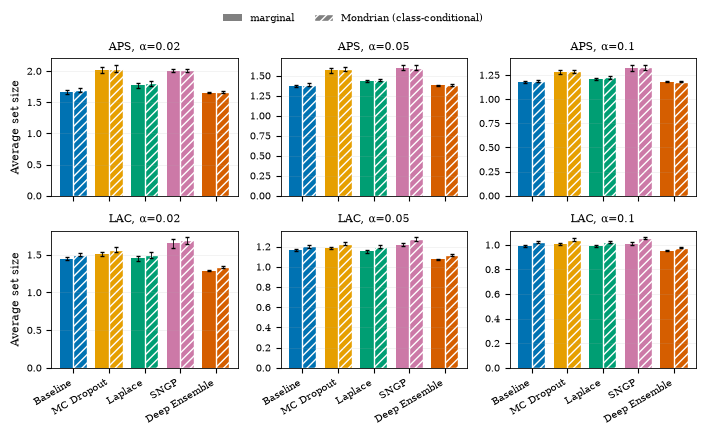

In [24]:
# Figure: marginal vs Mondrian set size, per method / score / alpha
fig, axes = plt.subplots(2, 3, figsize=(FULL_W, 4.2), sharex=True)
x = np.arange(len(METHODS)); w = 0.38
for i, sc in enumerate(SCORES):
    for j, a in enumerate(FOCUS):
        ax = axes[i, j]
        marg = [[r["sizes"]["raw"][sc][gi(a)] for r in runs if r["model"] == m] for m in METHODS]
        mond = [[r["mond"][a][sc]["avg_set_size"] for r in runs if r["model"] == m] for m in METHODS]
        for k, m in enumerate(METHODS):
            ax.bar(k - w / 2, np.mean(marg[k]), w, yerr=np.std(marg[k], ddof=1), color=COLOR[m], capsize=1.5,
                   error_kw=dict(lw=0.6))
            ax.bar(k + w / 2, np.mean(mond[k]), w, yerr=np.std(mond[k], ddof=1), color=COLOR[m], hatch="////",
                   edgecolor="white", capsize=1.5, error_kw=dict(lw=0.6))
        ax.set_title(f"{SHORT[sc]}, α={a}")
        ax.set_xticks(x); ax.set_xticklabels([LABEL[m] for m in METHODS], rotation=30, ha="right")
        if j == 0: ax.set_ylabel("Average set size")
        ax.grid(axis="y", alpha=0.25, lw=0.4)
fig.legend([Patch(facecolor="gray"), Patch(facecolor="gray", hatch="////", edgecolor="white")],
           ["marginal", "Mondrian (class-conditional)"], loc="upper center", ncol=2, frameon=False,
           bbox_to_anchor=(0.5, 1.03))
fig.tight_layout(rect=(0, 0, 1, 0.97)); finish(fig, "fig_mondrian_price")

## 3. Per-class coverage of the marginal sets

In [25]:
n_per_class = len(np.load(DEFAULT_RESULTS_DIR / f"{runs[0]['tag']}.npz")["test_labels"]) // 10
rng = np.random.RandomState(0)
sim = rng.binomial(n_per_class, 0.9, size=(20000, 10)) / n_per_class
print(f"noise-only reference ({n_per_class} test pts/class, true coverage 0.90): "
      f"min class cov ≈ {sim.min(1).mean():.3f}, max-min gap ≈ {(sim.max(1) - sim.min(1)).mean():.3f}, "
      f"std across classes ≈ {sim.std(1).mean():.3f}")

body = []
for sc in SCORES:
    for a in (0.05, 0.10):
        for m in METHODS:
            pc = np.array([r["pc_cov"][a][sc] for r in runs if r["model"] == m])   # (seeds, K)
            mp = pc.mean(0)
            body.append([SHORT[sc], a, LABEL[m], f"{pc.min(1).mean():.3f}", f"{(pc.max(1) - pc.min(1)).mean():.3f}",
                         f"{pc.std(1).mean():.3f}", f"{CLASSES[int(mp.argmin())]} ({mp.min():.3f})",
                         f"{CLASSES[int(mp.argmax())]} ({mp.max():.3f})"])
show("Per-class coverage of the marginal sets (mean over seeds)",
     md_table(["score", "α", "method", "min class cov", "max-min", "std over classes", "worst class", "best class"], body))

noise-only reference (1200 test pts/class, true coverage 0.90): min class cov ≈ 0.886, max-min gap ≈ 0.027, std across classes ≈ 0.008


**Per-class coverage of the marginal sets (mean over seeds)**

| score | α | method | min class cov | max-min | std over classes | worst class | best class |
|---|---|---|---|---|---|---|---|
| APS | 0.05 | Baseline | 0.931 | 0.033 | 0.011 | bird (0.933) | automobile (0.961) |
| APS | 0.05 | MC Dropout | 0.933 | 0.030 | 0.008 | bird (0.934) | automobile (0.957) |
| APS | 0.05 | Laplace | 0.931 | 0.031 | 0.009 | bird (0.932) | automobile (0.959) |
| APS | 0.05 | SNGP | 0.935 | 0.027 | 0.008 | bird (0.940) | frog (0.957) |
| APS | 0.05 | Deep Ensemble | 0.935 | 0.024 | 0.007 | bird (0.936) | automobile (0.955) |
| APS | 0.1 | Baseline | 0.876 | 0.043 | 0.015 | cat (0.878) | frog (0.915) |
| APS | 0.1 | MC Dropout | 0.877 | 0.037 | 0.011 | bird (0.877) | airplane (0.908) |
| APS | 0.1 | Laplace | 0.876 | 0.044 | 0.013 | bird (0.876) | airplane (0.913) |
| APS | 0.1 | SNGP | 0.881 | 0.036 | 0.011 | bird (0.884) | frog (0.914) |
| APS | 0.1 | Deep Ensemble | 0.882 | 0.031 | 0.009 | bird (0.885) | frog (0.909) |
| LAC | 0.05 | Baseline | 0.907 | 0.073 | 0.025 | cat (0.907) | truck (0.978) |
| LAC | 0.05 | MC Dropout | 0.911 | 0.068 | 0.024 | cat (0.912) | truck (0.978) |
| LAC | 0.05 | Laplace | 0.905 | 0.074 | 0.025 | cat (0.905) | truck (0.977) |
| LAC | 0.05 | SNGP | 0.912 | 0.064 | 0.021 | cat (0.914) | truck (0.975) |
| LAC | 0.05 | Deep Ensemble | 0.900 | 0.079 | 0.027 | cat (0.900) | automobile (0.978) |
| LAC | 0.1 | Baseline | 0.797 | 0.160 | 0.050 | cat (0.797) | truck (0.952) |
| LAC | 0.1 | MC Dropout | 0.802 | 0.156 | 0.051 | cat (0.802) | automobile (0.958) |
| LAC | 0.1 | Laplace | 0.792 | 0.165 | 0.052 | cat (0.792) | automobile (0.955) |
| LAC | 0.1 | SNGP | 0.808 | 0.147 | 0.048 | cat (0.808) | truck (0.952) |
| LAC | 0.1 | Deep Ensemble | 0.790 | 0.166 | 0.054 | cat (0.790) | automobile (0.956) |

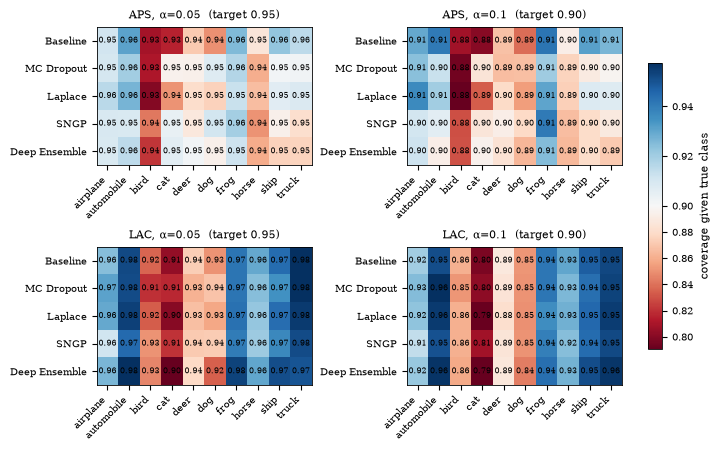

In [26]:
# Heatmap: per-class coverage of the marginal sets (mean over seeds)
fig, axes = plt.subplots(2, 2, figsize=(FULL_W, 4.4), layout="constrained")
for i, sc in enumerate(SCORES):
    for j, a in enumerate((0.05, 0.10)):
        ax = axes[i, j]
        M = np.array([np.mean([r["pc_cov"][a][sc] for r in runs if r["model"] == m], axis=0) for m in METHODS])
        im = ax.imshow(M, cmap="RdBu", norm=TwoSlopeNorm(vcenter=1 - a, vmin=min(M.min(), 1 - a - 0.02),
                                                         vmax=max(M.max(), 1 - a + 0.02)), aspect="auto")
        ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
        ax.set_yticks(range(len(METHODS))); ax.set_yticklabels([LABEL[m] for m in METHODS])
        for p in range(M.shape[0]):
            for q in range(M.shape[1]):
                ax.text(q, p, f"{M[p, q]:.2f}", ha="center", va="center", fontsize=5.5)
        ax.set_title(f"{SHORT[sc]}, α={a}  (target {1 - a:.2f})")
fig.colorbar(im, ax=axes, shrink=0.8, label="coverage given true class")
finish(fig, "fig_per_class_coverage")

## 4. Error detection and set-size breakdown

In [27]:
cols = [("1−max prob", lambda r: r["auroc_unc"]["conf"]), ("entropy", lambda r: r["auroc_unc"]["entropy"])]
for sc in SCORES:
    for a in (0.10, 0.05):
        cols.append((f"{SHORT[sc]} size α={a}", lambda r, sc=sc, a=a: r["auroc"][a][sc]))
body = []
for m in METHODS:
    rs = [r for r in runs if r["model"] == m]; cells = [LABEL[m]]
    for _, f in cols:
        v = np.array([f(r) for r in rs]); cells.append(f"{v.mean():.4f} ± {v.std(ddof=1):.4f}")
    body.append(cells)
show("AUROC for detecting top-1 errors (mean ± std over seeds)", md_table(["method"] + [c[0] for c in cols], body))

**AUROC for detecting top-1 errors (mean ± std over seeds)**

| method | 1−max prob | entropy | APS size α=0.1 | APS size α=0.05 | LAC size α=0.1 | LAC size α=0.05 |
|---|---|---|---|---|---|---|
| Baseline | 0.9154 ± 0.0038 | 0.9146 ± 0.0037 | 0.8045 ± 0.0124 | 0.8470 ± 0.0079 | 0.4642 ± 0.0214 | 0.7761 ± 0.0116 |
| MC Dropout | 0.9133 ± 0.0021 | 0.9099 ± 0.0027 | 0.8251 ± 0.0042 | 0.8574 ± 0.0054 | 0.4933 ± 0.0190 | 0.7923 ± 0.0094 |
| Laplace | 0.9154 ± 0.0038 | 0.9122 ± 0.0041 | 0.8179 ± 0.0059 | 0.8522 ± 0.0045 | 0.4618 ± 0.0180 | 0.7792 ± 0.0072 |
| SNGP | 0.9076 ± 0.0016 | 0.9054 ± 0.0022 | 0.8162 ± 0.0034 | 0.8561 ± 0.0041 | 0.5097 ± 0.0227 | 0.7978 ± 0.0022 |
| Deep Ensemble | 0.9318 ± 0.0020 | 0.9244 ± 0.0026 | 0.8413 ± 0.0052 | 0.8707 ± 0.0062 | 0.3335 ± 0.0087 | 0.6971 ± 0.0117 |

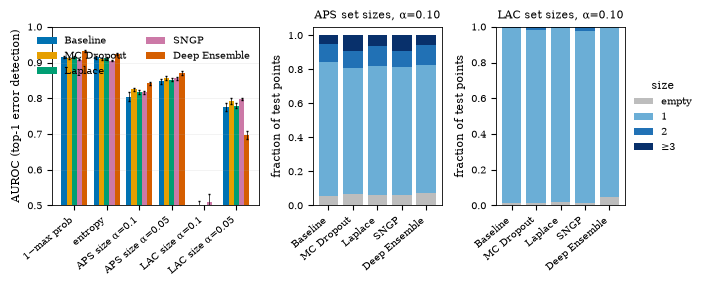

In [28]:
# Figure: AUROC bars + set-size breakdown (empty / singleton / 2 / >=3)
fig, axes = plt.subplots(1, 3, figsize=(FULL_W, 2.9), gridspec_kw=dict(width_ratios=[1.6, 1, 1]))
names = [c[0] for c in cols]; wb = 0.8 / len(METHODS)
for k, m in enumerate(METHODS):
    rs = [r for r in runs if r["model"] == m]
    vals = [np.mean([f(r) for r in rs]) for _, f in cols]; errs = [np.std([f(r) for r in rs], ddof=1) for _, f in cols]
    axes[0].bar(np.arange(len(cols)) + (k - (len(METHODS) - 1) / 2) * wb, vals, wb, yerr=errs, color=COLOR[m],
                label=LABEL[m], capsize=1, error_kw=dict(lw=0.5))
axes[0].set_xticks(range(len(cols))); axes[0].set_xticklabels(names, rotation=40, ha="right")
axes[0].set_ylabel("AUROC (top-1 error detection)"); axes[0].set_ylim(0.5, 1.0); axes[0].grid(axis="y", alpha=0.25, lw=0.4)
axes[0].legend(ncol=2, frameon=False, loc="upper right")

lab = ["empty", "1", "2", "≥3"]; shades = ["#bdbdbd", "#6baed6", "#2171b5", "#08306b"]
for ax, sc in zip(axes[1:], SCORES):
    D = np.array([np.mean([r["dist"][0.10][sc] for r in runs if r["model"] == m], axis=0) for m in METHODS])
    bottom = np.zeros(len(METHODS))
    for q in range(4):
        ax.bar(range(len(METHODS)), D[:, q], bottom=bottom, color=shades[q], label=lab[q]); bottom += D[:, q]
    ax.set_xticks(range(len(METHODS))); ax.set_xticklabels([LABEL[m] for m in METHODS], rotation=40, ha="right")
    ax.set_title(f"{SHORT[sc]} set sizes, α=0.10"); ax.set_ylabel("fraction of test points")
axes[2].legend(title="size", frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.tight_layout(); finish(fig, "fig_uncertainty_signal")

## 5. Calibration vs. discrimination: temperature-scaling intervention

For each run, probabilities are rescaled with a single temperature **T** fitted on the calibration split. This changes calibration (ECE, NLL) but not accuracy or each input's class ordering, so it isolates the calibration effect on conformal sets. Per-method averages over 5 seeds.

In [34]:
body = []
for m in METHODS:
    f = lambda k: mean_std(m, k)[0]
    cells = [LABEL[m], f"{f('T'):.2f}", f"{f('ece'):.4f} → {f('ece_ts'):.4f}", f"{f('nll'):.4f} → {f('nll_ts'):.4f}"]
    for s in ("aps", "lac"):
        for a in (0.05, 0.10):
            raw, ts = f(f"{s}_size_raw_{ak(a)}"), f(f"{s}_size_ts_{ak(a)}")
            cells.append(f"{raw:.3f} → {ts:.3f} ({100 * (ts / raw - 1):+.1f}%)")
    body.append(cells)
show("Effect of temperature scaling",
     md_table(["method", "mean T", "ECE", "NLL", "APS size α=0.05", "APS size α=0.10",
               "LAC size α=0.05", "LAC size α=0.10"], body))

**Effect of temperature scaling**

| method | mean T | ECE | NLL | APS size α=0.05 | APS size α=0.10 | LAC size α=0.05 | LAC size α=0.10 |
|---|---|---|---|---|---|---|---|
| Baseline | 1.30 | 0.0273 → 0.0079 | 0.2918 → 0.2780 | 1.371 → 1.503 (+9.6%) | 1.178 → 1.255 (+6.6%) | 1.163 → 1.162 (-0.1%) | 0.991 → 0.992 (+0.1%) |
| MC Dropout | 1.01 | 0.0115 → 0.0106 | 0.2994 → 0.2993 | 1.566 → 1.573 (+0.5%) | 1.280 → 1.284 (+0.3%) | 1.188 → 1.187 (-0.0%) | 1.004 → 1.004 (-0.0%) |
| Laplace | 1.07 | 0.0130 → 0.0069 | 0.2803 → 0.2790 | 1.433 → 1.469 (+2.5%) | 1.211 → 1.231 (+1.7%) | 1.156 → 1.155 (-0.1%) | 0.990 → 0.990 (+0.0%) |
| SNGP | 0.90 | 0.0286 → 0.0220 | 0.3379 → 0.3327 | 1.598 → 1.561 (-2.3%) | 1.322 → 1.293 (-2.2%) | 1.219 → 1.226 (+0.6%) | 1.010 → 1.010 (+0.0%) |
| Deep Ensemble | 0.89 | 0.0154 → 0.0058 | 0.2212 → 0.2197 | 1.380 → 1.329 (-3.7%) | 1.180 → 1.149 (-2.7%) | 1.075 → 1.075 (+0.0%) | 0.952 → 0.950 (-0.1%) |

In [35]:
def diff_se(m1, m2, key):
    a = np.array([r[key] for r in rows if r["model"] == m1]); b = np.array([r[key] for r in rows if r["model"] == m2])
    return float(a.mean() - b.mean()), float(np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b)))

decomp = {}      # (score, alpha, method) -> (total, refinement, calibration)
body = []
for s in ("aps", "lac"):
    for a in FOCUS:
        for m in METHODS[1:]:
            tot, tot_se = diff_se(m, "baseline", f"{s}_size_raw_{ak(a)}")
            ref, ref_se = diff_se(m, "baseline", f"{s}_size_ts_{ak(a)}")
            decomp[(s, a, m)] = (tot, ref, tot - ref)
            body.append([s.upper(), a, LABEL[m], f"{tot:+.3f} ± {tot_se:.3f}", f"{ref:+.3f} ± {ref_se:.3f}", f"{tot - ref:+.3f}"])
show("Set-size gap vs. baseline: total = refinement + calibration part",
     md_table(["score", "α", "method", "total gap (raw)", "refinement gap (after TS)", "calibration part"], body))

**Set-size gap vs. baseline: total = refinement + calibration part**

| score | α | method | total gap (raw) | refinement gap (after TS) | calibration part |
|---|---|---|---|---|---|
| APS | 0.02 | MC Dropout | +0.351 ± 0.023 | +0.173 ± 0.028 | +0.178 |
| APS | 0.02 | Laplace | +0.106 ± 0.021 | -0.032 ± 0.026 | +0.138 |
| APS | 0.02 | SNGP | +0.339 ± 0.015 | +0.106 ± 0.019 | +0.232 |
| APS | 0.02 | Deep Ensemble | -0.012 ± 0.012 | -0.291 ± 0.017 | +0.279 |
| APS | 0.05 | MC Dropout | +0.195 ± 0.014 | +0.071 ± 0.017 | +0.125 |
| APS | 0.05 | Laplace | +0.062 ± 0.009 | -0.034 ± 0.013 | +0.095 |
| APS | 0.05 | SNGP | +0.227 ± 0.015 | +0.059 ± 0.018 | +0.169 |
| APS | 0.05 | Deep Ensemble | +0.009 ± 0.007 | -0.173 ± 0.011 | +0.182 |
| APS | 0.1 | MC Dropout | +0.103 ± 0.010 | +0.029 ± 0.012 | +0.074 |
| APS | 0.1 | Laplace | +0.034 ± 0.007 | -0.024 ± 0.010 | +0.057 |
| APS | 0.1 | SNGP | +0.144 ± 0.014 | +0.038 ± 0.014 | +0.106 |
| APS | 0.1 | Deep Ensemble | +0.003 ± 0.006 | -0.107 ± 0.008 | +0.109 |
| LAC | 0.02 | MC Dropout | +0.067 ± 0.016 | +0.076 ± 0.018 | -0.009 |
| LAC | 0.02 | Laplace | +0.003 ± 0.020 | +0.012 ± 0.021 | -0.009 |
| LAC | 0.02 | SNGP | +0.203 ± 0.029 | +0.224 ± 0.032 | -0.020 |
| LAC | 0.02 | Deep Ensemble | -0.157 ± 0.012 | -0.150 ± 0.014 | -0.007 |
| LAC | 0.05 | MC Dropout | +0.024 ± 0.007 | +0.025 ± 0.007 | -0.001 |
| LAC | 0.05 | Laplace | -0.008 ± 0.008 | -0.007 ± 0.008 | -0.001 |
| LAC | 0.05 | SNGP | +0.056 ± 0.009 | +0.064 ± 0.010 | -0.008 |
| LAC | 0.05 | Deep Ensemble | -0.088 ± 0.005 | -0.087 ± 0.005 | -0.002 |
| LAC | 0.1 | MC Dropout | +0.013 ± 0.005 | +0.011 ± 0.004 | +0.001 |
| LAC | 0.1 | Laplace | -0.002 ± 0.004 | -0.002 ± 0.004 | +0.001 |
| LAC | 0.1 | SNGP | +0.019 ± 0.006 | +0.018 ± 0.006 | +0.001 |
| LAC | 0.1 | Deep Ensemble | -0.040 ± 0.003 | -0.042 ± 0.003 | +0.002 |

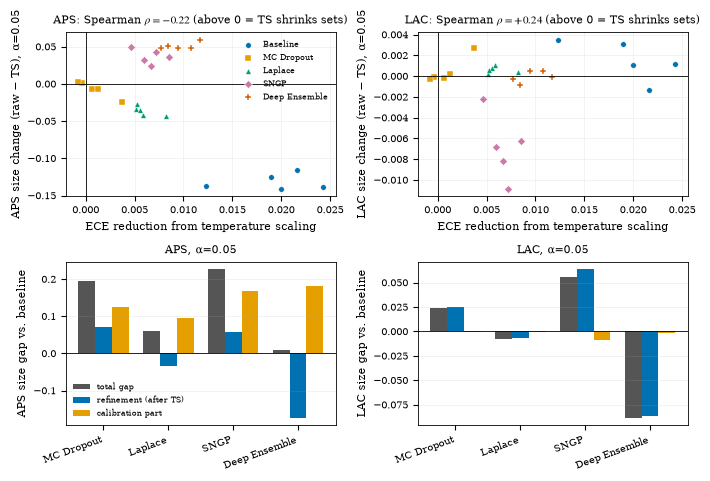

In [36]:
# Figures: (a) does making probabilities better calibrated (ranking fixed) shrink sets?  (b) gap decomposition
fig, axes = plt.subplots(2, 2, figsize=(FULL_W, 4.8))
a = ALPHA_DECOMP
for ax, s in zip(axes[0], ("aps", "lac")):
    x_, y_ = col("d_ece"), col(f"{s}_dsize_{ak(a)}")
    for m in METHODS:
        g = [r for r in rows if r["model"] == m]
        ax.scatter([r["d_ece"] for r in g], [r[f"{s}_dsize_{ak(a)}"] for r in g], color=COLOR[m], marker=MARKER[m],
                   s=16, edgecolor="white", linewidth=0.3, label=LABEL[m])
    rho = stats.spearmanr(x_, y_)[0]
    ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
    ax.set_xlabel("ECE reduction from temperature scaling"); ax.set_ylabel(f"{s.upper()} size change (raw − TS), α={a}")
    ax.set_title(rf"{s.upper()}: Spearman $\rho={rho:+.2f}$ (above 0 = TS shrinks sets)"); ax.grid(alpha=0.25, lw=0.4)
axes[0, 0].legend(frameon=False, fontsize=6)
for ax, s in zip(axes[1], ("aps", "lac")):
    ws = 0.26
    for q, (lab_, c_) in enumerate((("total gap", "#555555"), ("refinement (after TS)", "#0072B2"), ("calibration part", "#E69F00"))):
        vals = [decomp[(s, a, m)][q] for m in METHODS[1:]]
        ax.bar(np.arange(len(METHODS) - 1) + (q - 1) * ws, vals, ws, color=c_, label=lab_)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_xticks(range(len(METHODS) - 1)); ax.set_xticklabels([LABEL[m] for m in METHODS[1:]], rotation=20, ha="right")
    ax.set_ylabel(f"{s.upper()} size gap vs. baseline"); ax.set_title(f"{s.upper()}, α={a}"); ax.grid(axis="y", alpha=0.25, lw=0.4)
axes[1, 0].legend(frameon=False, fontsize=6)
fig.tight_layout(); finish(fig, "fig_calibration_intervention")

## 6. Rank correlations with calibration separated from refinement

Efficiency = AUC of set size over α ∈ [0.02, 0.10] (APS and LAC). Predictors:

- **ECE:** top-label calibration error;
- **NLL calibration gap** = NLL − NLL after temperature scaling: the part of the loss that one scalar T can remove (calibration loss);
- **NLL after TS** = the loss that remains after recalibration (refinement / discrimination);
- **accuracy**, for reference.

*Within-method* removes each method's mean first, showing whether seed-to-seed variation points the same way.

In [32]:
def demean_by_model(key):
    v = col(key).copy()
    for m in METHODS:
        i = [k for k, r in enumerate(rows) if r["model"] == m]; v[i] -= v[i].mean()
    return v
def sp(x, y):
    if np.std(x) == 0 or np.std(y) == 0: return np.nan, np.nan
    r, p = stats.spearmanr(x, y); return float(r), float(p)

preds = [("accuracy", "accuracy"), ("ece", "ECE"), ("nll_gap", "NLL calibration gap (NLL − NLL_TS)"), ("nll_ts", "NLL after TS (refinement)")]
effs = [("aps_auc_raw", "APS AUC"), ("lac_auc_raw", "LAC AUC")]
body = []
for key, name in preds:
    cells = [name]
    for ek, _ in effs:
        for dm in (False, True):
            x = demean_by_model(key) if dm else col(key); y = demean_by_model(ek) if dm else col(ek)
            r, p = sp(x, y); cells.append(f"{r:+.2f} (p={p:.3f})")
    body.append(cells)
hdr = ["predictor"] + [f"{n}, {kind}" for _, n in effs for kind in ("pooled", "within-method")]
show("Spearman ρ with restricted-AUC set size (n = 25)", md_table(hdr, body))

body = []
for s in ("aps", "lac"):
    for a in FOCUS:
        x, y = col("d_ece"), col(f"{s}_dsize_{ak(a)}")
        r_p, p_p = sp(x, y); r_w, p_w = sp(demean_by_model("d_ece"), demean_by_model(f"{s}_dsize_{ak(a)}"))
        body.append([s.upper(), a, f"{y.mean():+.4f}", f"{(y > 0).mean():.2f}", f"{r_p:+.2f} (p={p_p:.3f})", f"{r_w:+.2f} (p={p_w:.3f})"])
show("Temperature-scaling intervention: change in set size (raw − Temp. Scaling.)",
     md_table(["score", "α", "mean Δsize", "fraction of runs with smaller sets", "ρ(ΔECE, Δsize) pooled", "within-method"], body))

**Spearman ρ with restricted-AUC set size (n = 25)**

| predictor | APS AUC, pooled | APS AUC, within-method | LAC AUC, pooled | LAC AUC, within-method |
|---|---|---|---|---|
| accuracy | -0.84 (p=0.000) | -0.42 (p=0.037) | -0.93 (p=0.000) | -0.55 (p=0.004) |
| ECE | -0.13 (p=0.531) | +0.12 (p=0.558) | +0.15 (p=0.461) | +0.13 (p=0.531) |
| NLL calibration gap (NLL − NLL_TS) | -0.38 (p=0.064) | +0.19 (p=0.351) | -0.00 (p=0.983) | +0.10 (p=0.638) |
| NLL after TS (refinement) | +0.81 (p=0.000) | +0.49 (p=0.014) | +0.94 (p=0.000) | +0.53 (p=0.007) |

**Temperature-scaling intervention: change in set size (raw − Temp. Scaling.)**

| score | α | mean Δsize | fraction of runs with smaller sets | ρ(ΔECE, Δsize) pooled | within-method |
|---|---|---|---|---|---|
| APS | 0.02 | -0.0270 | 0.48 | -0.19 (p=0.359) | -0.25 (p=0.225) |
| APS | 0.05 | -0.0175 | 0.48 | -0.22 (p=0.280) | -0.32 (p=0.118) |
| APS | 0.1 | -0.0082 | 0.44 | -0.20 (p=0.345) | -0.53 (p=0.006) |
| LAC | 0.02 | +0.0002 | 0.60 | +0.51 (p=0.009) | -0.25 (p=0.228) |
| LAC | 0.05 | -0.0009 | 0.52 | +0.24 (p=0.252) | -0.08 (p=0.718) |
| LAC | 0.1 | +0.0000 | 0.52 | -0.23 (p=0.277) | +0.10 (p=0.619) |

# 7 Save tables and results analysis

In [33]:
# Save tables (markdown) and the per-run numbers
with open(OUT_DIR / "tables.md", "w", encoding="utf-8") as f:
    for title, t in TABLES: f.write(f"### {title}\n\n{t}\n\n")
with open(OUT_DIR / "mondrian_analysis_rows.json", "w") as f:
    json.dump(rows, f, indent=2)
print("tables ->", OUT_DIR / "tables.md"); print("figures ->", FIG_DIR)

tables -> D:\University\Fourth Year - 2026-2027\CISC 473\CISC-473-P23\results\calibration_efficiency\mondrian_analysis\tables.md
figures -> D:\University\Fourth Year - 2026-2027\CISC 473\CISC-473-P23\results\calibration_efficiency\mondrian_analysis\figures
